# CNN: sáu lớp học được, Scratch – Keras – PyTorch

    Notebook bổ sung cho báo cáo Chương 3–4. Mỗi nhóm cell trình bày
    **công thức → hàm → code → kết quả → giải thích**.
    Chọn Run All trong môi trường `.venv` của dự án. Notebook dùng dữ liệu
    VN-Index thật đã xử lý và chia theo thời gian, không tải mạng.
    Chỉ dùng 256 mẫu train, 128 validation và 256 test để demo trong thời gian ngắn;
    đây là thực nghiệm trên tập con, không thay thế benchmark toàn bộ dữ liệu.

In [1]:
# Cell CNN-01
import os, sys, json, time, inspect, copy
from pathlib import Path
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[key] = '2'
os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'src/tieuluan').exists())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
OUT = ROOT/'results/tieuluan/complete/notebooks'
OUT.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT)

Project: E:\WINDOW\Project\intelligent-system-assignment-01


## Dữ liệu và kiểu đầu vào–đầu ra

    Giữ đúng ranh giới thời gian của bộ dữ liệu đã chuẩn hóa từ train.
    Lấy 256 mẫu cuối của train, 128 mẫu đầu val và 256 mẫu đầu test.
    In ngày quan sát/ngày nhãn và phân bố lớp để người xem kiểm tra.
    `train_x`, `val_x`, `test_x` là tensor; nhãn có shape B × 1.

In [2]:
# Cell CNN-02
KIND = 'cnn'
representation = 'image' if KIND == 'cnn' else 'sequence'
with np.load(ROOT/'data/tieuluan/processed/vnindex.npz') as archive:
    data = {}
    ranges = {'train':slice(-256,None), 'val':slice(0,128),
              'test':slice(0,256)}
    inventory = []
    for split, selection in ranges.items():
        data[split+'_x'] = archive[split+'_'+representation][selection].copy()
        data[split+'_y'] = archive[split+'_y'][selection].reshape(-1,1).copy()
        dates = archive[split+'_date'][selection]
        targets = archive[split+'_target_date'][selection]
        inventory.append({'split':split, 'n':len(dates),
            'first':str(dates[0]), 'last_target':str(targets[-1]),
            'positive':int(data[split+'_y'].sum())})
    assert archive['train_target_date'].max() < archive['val_date'].min()
    assert archive['val_target_date'].max() < archive['test_date'].min()
display(pd.DataFrame(inventory))
print('X:', data['train_x'].shape, 'y:', data['train_y'].shape)

,split,n,first,last_target,positive
0,train,256,2018-12-20,2019-12-31,129
1,val,128,2020-01-02,2020-07-10,74
2,test,256,2023-01-03,2024-01-11,153


X: (256, 1, 20, 20) y: (256, 1)


## 1. Biểu diễn mạng là hợp các hàm

    CNN: z = D6 ∘ ReLU ∘ D5 ∘ Flatten ∘ ReLU ∘ C4 ∘ ReLU ∘ C3
    ∘ ReLU ∘ C2 ∘ ReLU ∘ C1 (X).

    RNN/LSTM: z = Dense ∘ LastStep ∘ Cell5 ∘ Cell4 ∘ Cell3 ∘ Cell2 ∘ Cell1 (X).

    Đọc từ phải sang trái. CNN có 4 Conv + 2 Dense; RNN/LSTM có 5 lớp hồi quy
    + 1 Dense. ReLU, Flatten, LastStep và số bước thời gian không được đếm thành
    lớp học được. Xác suất chỉ tính bằng sigmoid sau logit.

In [3]:
# Cell CNN-03
from src.tieuluan.scratch.core import Sequential
from src.tieuluan.scratch.layers import Conv2d, Dense, Flatten, ReLU
from src.tieuluan.scratch.recurrent import SimpleRNN, LSTM, LastStep

def scratch_deep(kind, seed=42):
    rng = np.random.default_rng(seed)
    if kind == 'cnn':
        layers = []
        for cin, cout in [(1, 4), (4, 4), (4, 8), (8, 8)]:
            layers += [Conv2d(cin, cout, 3, rng=rng), ReLU()]
        return Sequential(*layers, Flatten(),
                          Dense(8*12*12, 8, rng=rng), ReLU(),
                          Dense(8, 1, rng=rng))
    cell = {'rnn': SimpleRNN, 'lstm': LSTM}[kind]
    layers = [cell(1, 8, rng=rng)]
    layers += [cell(8, 8, rng=rng) for _ in range(4)]
    return Sequential(*layers, LastStep(), Dense(8, 1, rng=rng))

### Giải thích `scratch_deep`

    Đầu vào là `kind` và seed; đầu ra là Sequential tự viết bằng NumPy.
    CNN: mỗi Conv giảm cạnh ảnh hai đơn vị, từ 20 xuống 12, nên Dense nhận
    8 × 12 × 12 = 1.152 giá trị. RNN/LSTM: lớp đầu nhận một đặc trưng,
    các lớp sau nhận tám chiều; chỉ lấy bước cuối sau lớp thứ năm.
    Mỗi lớp Scratch có forward/backward riêng, không gọi autograd.

In [4]:
# Cell CNN-04
def keras_deep(kind, seed=42):
    import keras
    keras.utils.set_random_seed(seed)
    if kind == 'cnn':
        x = keras.Input((1, 20, 20))
        z = keras.layers.Permute((2, 3, 1))(x)
        for width in [4, 4, 8, 8]:
            z = keras.layers.Conv2D(width, 3, activation='relu')(z)
        z = keras.layers.Permute((3, 1, 2))(z)
        z = keras.layers.Flatten()(z)
        z = keras.layers.Dense(8, activation='relu')(z)
    else:
        x = keras.Input((20, 1))
        z = x
        cell = {'rnn': keras.layers.SimpleRNN,
                'lstm': keras.layers.LSTM}[kind]
        for depth in range(5):
            z = cell(8, return_sequences=(depth < 4))(z)
    return keras.Model(x, keras.layers.Dense(1)(z))

### Giải thích `keras_deep`

    Keras dùng Functional API. Permute đổi NCHW sang NHWC cho Conv và đưa về
    NCHW trước Flatten để khớp thứ tự với Scratch. Với hồi quy, bốn lớp đầu
    `return_sequences=True`; lớp cuối trả vector. Dense cuối chưa sigmoid,
    để dùng BCE trực tiếp từ logit.

In [5]:
# Cell CNN-05
def torch_deep(kind, seed=42):
    import torch
    from torch import nn
    torch.manual_seed(seed)
    if kind == 'cnn':
        layers = []
        for cin, cout in [(1, 4), (4, 4), (4, 8), (8, 8)]:
            layers += [nn.Conv2d(cin, cout, 3), nn.ReLU()]
        return nn.Sequential(*layers, nn.Flatten(),
                             nn.Linear(8*12*12, 8), nn.ReLU(),
                             nn.Linear(8, 1))

    class Stacked(nn.Module):
        def __init__(self):
            super().__init__()
            cell = {'rnn': nn.RNN, 'lstm': nn.LSTM}[kind]
            self.cells = nn.ModuleList([cell(1, 8, batch_first=True)])
            self.cells.extend([cell(8, 8, batch_first=True)
                               for _ in range(4)])
            self.head = nn.Linear(8, 1)

        def forward(self, x):
            for cell in self.cells:
                x, _ = cell(x)
            return self.head(x[:, -1])
    return Stacked()

### Giải thích `torch_deep` và `Stacked.forward`

    CNN dùng nn.Sequential; hồi quy dùng ModuleList. Mỗi cell trả về toàn bộ
    chuỗi và trạng thái cuối; forward truyền chuỗi sang cell tiếp theo,
    rồi lấy x[:, -1] đưa qua Linear. `batch_first=True` giữ shape B × T × D.

In [6]:
# Cell CNN-06
def align_weights(source, target, framework, kind):
    """Same effective weights and same trainable parameter counts."""
    weighted = [l for l in source.layers if l.parameters()]
    if framework == 'keras':
        targets = [l for l in target.layers if l.weights]
        for s, t in zip(weighted, targets, strict=True):
            if isinstance(s, Conv2d):
                t.set_weights([s.weight.value.transpose(2, 3, 1, 0),
                               s.bias.value])
            elif isinstance(s, Dense):
                t.set_weights([s.weight.value.T, s.bias.value])
            else:
                t.set_weights([s.weight_ih.value.T,
                               s.weight_hh.value.T,
                               s.bias_ih.value + s.bias_hh.value])
    else:
        import torch
        with torch.no_grad():
            for s, t in zip(source.parameters(), target.parameters(),
                            strict=True):
                t.copy_(torch.from_numpy(s.value))
        if kind != 'cnn':
            for cell in target.cells:
                cell.bias_hh_l0.requires_grad_(False)
    if kind != 'cnn':
        for layer in weighted[:-1]:
            layer.bias_hh.grad[...] = 0

### Giải thích `align_weights`

    Cùng seed không bảo đảm cùng trọng số giữa ba thư viện. Hàm sao chép cùng
    trọng số hiệu dụng; đổi trục kernel Conv và chuyển vị Dense cho Keras.
    Với hồi quy, giữ bias thứ hai bằng không để số tham số học khớp một bias
    của Keras. Kiểm tra logit ban đầu trong cell huấn luyện sẽ phát hiện lệch.

In [7]:
# Cell CNN-07
# Quan sát hợp hàm bằng cách in shape sau từng hàm, trên một mẫu thật.
trace_model = scratch_deep(KIND)
value = data['train_x'][:1]
trace = []
for index, layer in enumerate(trace_model.layers, 1):
    before = value.shape
    value = layer.forward(value)
    trace.append({'step':index, 'function':type(layer).__name__,
                  'input':str(before), 'output':str(value.shape)})
display(pd.DataFrame(trace))
print('Logit:', value.ravel())
print('Sigmoid:', (0.5*(1+np.tanh(value/2))).ravel())

,step,function,input,output
0,1,Conv2d,"(1, 1, 20, 20)","(1, 4, 18, 18)"
1,2,ReLU,"(1, 4, 18, 18)","(1, 4, 18, 18)"
2,3,Conv2d,"(1, 4, 18, 18)","(1, 4, 16, 16)"
3,4,ReLU,"(1, 4, 16, 16)","(1, 4, 16, 16)"
4,5,Conv2d,"(1, 4, 16, 16)","(1, 8, 14, 14)"
5,6,ReLU,"(1, 8, 14, 14)","(1, 8, 14, 14)"
6,7,Conv2d,"(1, 8, 14, 14)","(1, 8, 12, 12)"
7,8,ReLU,"(1, 8, 12, 12)","(1, 8, 12, 12)"
8,9,Flatten,"(1, 8, 12, 12)","(1, 1152)"
9,10,Dense,"(1, 1152)","(1, 8)"


Logit: [-0.00505902]
Sigmoid: [0.49873525]


## 2. Giải thích bên trong hàm forward và backward

    Cell tiếp theo in mã thực của các lớp được dùng, giúp giải thích phép tính
    thay vì chỉ nói “gọi thư viện”. Với Dense: dW=GᵀX, db=sum(G), dX=GW.
    Với RNN/LSTM: backward chạy ngược thời gian và cộng gradient vào cùng trọng số.
    LSTM duy trì gradient ô nhớ c riêng với gradient trạng thái h.
    Đối chiếu từng dòng mã với công thức trong Chương 3/4.

In [8]:
# Cell CNN-08
primitives = [Conv2d, ReLU, Flatten, Dense] if KIND == 'cnn' else [
    SimpleRNN if KIND == 'rnn' else LSTM, LastStep, Dense]
for primitive in primitives:
    print(inspect.getsource(primitive))

class Conv2d(Module):
    """Tích chập 2 chiều cài bằng kỹ thuật im2col.

    Mỗi "cửa sổ" KH×KW của ảnh được duỗi thành một hàng của ma trận ``cols``; khi đó
    phép tích chập trở thành một phép nhân ma trận lớn (cols · Wᵀ) — cách các thư viện
    như Caffe từng dùng. Hỗ trợ stride, padding và dilation giống ``torch.nn.Conv2d``.
    """

    def __init__(self, in_channels, out_channels, kernel_size, *, stride=1, padding=0, dilation=1,
                 rng=None, dtype=np.float32):
        rng = rng or np.random.default_rng(0)
        self.kernel = _pair(kernel_size)
        self.stride, self.padding, self.dilation = _pair(stride), _pair(padding), _pair(dilation)
        kh, kw = self.kernel
        fan_in, fan_out = in_channels * kh * kw, out_channels * kh * kw
        self.weight = Parameter(glorot_uniform(rng, fan_in, fan_out, (out_channels, in_channels, kh, kw), dtype), "weight")
        self.bias = Parameter(np.zeros(out_channels, dtype=dtype), "bias")

    def output_shape(self, 

class ReLU(Module):
    def forward(self, x):
        self._mask = x > 0
        return np.where(self._mask, x, 0).astype(x.dtype, copy=False)

    def backward(self, grad):
        return grad * self._mask

class Flatten(Module):
    def forward(self, x):
        self._shape = x.shape
        return x.reshape(x.shape[0], -1)

    def backward(self, grad):
        return grad.reshape(self._shape)

class Dense(Module):
    """Lớp kết nối đầy đủ: y = x·Wᵀ + b."""

    def __init__(self, in_features: int, out_features: int, *, rng=None, dtype=np.float32):
        rng = rng or np.random.default_rng(0)
        self.weight = Parameter(glorot_uniform(rng, in_features, out_features, (out_features, in_features), dtype), "weight")
        self.bias = Parameter(np.zeros(out_features, dtype=dtype), "bias")
        self._x = None

    def forward(self, x):
        self._x = x
        return x @ self.weight.value.T + self.bias.value

    def backward(self, grad):
        self.weight.grad += grad.T @

In [9]:
# Cell CNN-09
def train_batch(model, framework, x, y, optimizer):
    """One actual optimization step, binary classification on logits."""
    if framework == 'scratch':
        from src.tieuluan.scratch.losses import BCEWithLogitsLoss
        from src.tieuluan.scratch.optim import clip_grad_norm
        model.train()
        model.zero_grad()
        loss = BCEWithLogitsLoss()
        value = loss.forward(model.forward(x), y)
        model.backward(loss.backward())
        # One effective bias, matching Keras and the frozen Torch bias.
        for layer in model.layers:
            if isinstance(layer, (SimpleRNN, LSTM)):
                layer.bias_hh.grad[...] = 0
        clip_grad_norm(model.parameters(), 1.0)
        optimizer.step()
        return value
    if framework == 'pytorch':
        import torch
        model.train()
        optimizer.zero_grad()
        loss = torch.nn.functional.binary_cross_entropy_with_logits(
            model(torch.from_numpy(x)), torch.from_numpy(y))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        return float(loss.detach())
    import tensorflow as tf
    with tf.GradientTape() as tape:
        logits = model(x, training=True)
        loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(
            labels=y, logits=logits))
    grads = tape.gradient(loss, model.trainable_variables)
    grads, _ = tf.clip_by_global_norm(grads, 1.0)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return float(loss.numpy())

### Giải thích `train_batch`

    Thứ tự bắt buộc: zero_grad → forward → BCE từ logit → backward → cắt chuẩn
    gradient → Adam.step. Scratch tự tính đạo hàm; PyTorch dùng autograd;
    Keras dùng GradientTape. Xóa gradient bias phụ ở Scratch trước Adam.
    Nếu quên zero_grad, gradient các batch cộng dồn sai thiết kế.
    Nếu sigmoid trước BCEWithLogits, mất mát nhận sai kiểu đầu vào.

In [10]:
# Cell CNN-10
from sklearn.metrics import roc_auc_score, accuracy_score
from src.tieuluan.scratch.optim import Adam
import torch, keras
torch.set_num_threads(2)

def logits_of(model, framework, x):
    """Logit B x 1; suy luận không xây graph gradient."""
    if framework == 'scratch':
        model.eval()
        return model.forward(x)
    if framework == 'pytorch':
        model.eval()
        with torch.no_grad():
            return model(torch.from_numpy(x)).numpy()
    return model(x, training=False).numpy()

def binary_loss(z, y):
    """BCE ổn định số từ logit, không sigmoid hai lần."""
    return float(np.mean(np.logaddexp(0, z) - y*z))

def snapshot(model, framework):
    if framework == 'scratch':
        return model.state_dict()
    if framework == 'pytorch':
        return copy.deepcopy(model.state_dict())
    return [w.copy() for w in model.get_weights()]

def restore(model, framework, state):
    if framework in ['scratch', 'pytorch']:
        model.load_state_dict(state)
    else:
        model.set_weights(state)

def run_comparison(kind, data, epochs=3, batch_size=32):
    """Huấn luyện trên train, chọn checkpoint bằng val, đọc test ở cuối."""
    models = {'scratch': scratch_deep(kind),
              'keras': keras_deep(kind),
              'pytorch': torch_deep(kind)}
    for fw in ['keras', 'pytorch']:
        align_weights(models['scratch'], models[fw], fw, kind)
    optimizers = {
        'scratch': Adam(models['scratch'].parameters(), lr=0.001),
        'keras': keras.optimizers.Adam(learning_rate=0.001, epsilon=1e-8),
        'pytorch': torch.optim.Adam(
            [p for p in models['pytorch'].parameters() if p.requires_grad],
            lr=0.001, eps=1e-8)}
    reference = logits_of(models['scratch'], 'scratch', data['train_x'][:4])
    rows, curves, predictions = [], {}, {}
    for fw, model in models.items():
        diff = float(np.max(np.abs(
            logits_of(model, fw, data['train_x'][:4])-reference)))
        assert diff < 1e-4
        best_loss, best_state, best_epoch = float('inf'), None, 0
        history = []
        # Cùng thứ tự mini-batch giữa các framework.
        rng = np.random.default_rng(2026)
        start = time.perf_counter()
        for epoch in range(epochs):
            order = rng.permutation(len(data['train_y']))
            losses = []
            for i in range(0, len(order), batch_size):
                ids = order[i:i+batch_size]
                losses.append(train_batch(model, fw,
                    data['train_x'][ids], data['train_y'][ids],
                    optimizers[fw]))
            val_loss = binary_loss(
                logits_of(model, fw, data['val_x']), data['val_y'])
            history.append({'epoch':epoch+1,
                'train_loss':float(np.mean(losses)), 'val_loss':val_loss})
            if val_loss < best_loss:
                best_loss = val_loss
                best_state = snapshot(model, fw)
                best_epoch = epoch+1
        restore(model, fw, best_state)
        # Test chỉ được đánh giá sau khi chọn checkpoint bằng validation.
        z = logits_of(model, fw, data['test_x']).reshape(-1)
        probability = 0.5*(1+np.tanh(z/2))
        target = data['test_y'].reshape(-1)
        assert np.isfinite(z).all()
        rows.append({'kind':kind, 'framework':fw,
            'trainable_layers':6, 'train_n':len(data['train_y']),
            'val_n':len(data['val_y']), 'test_n':len(target),
            'epochs':epochs, 'best_epoch':best_epoch,
            'val_loss':best_loss, 'test_bce':binary_loss(z,target),
            'test_auc':float(roc_auc_score(target,probability)),
            'test_accuracy':float(accuracy_score(target,probability>=0.5)),
            'initial_max_error':diff,
            'seconds':time.perf_counter()-start})
        curves[fw] = history
        predictions[fw] = probability.tolist()
    return models, rows, curves, predictions

### Giải thích các hàm huấn luyện/đánh giá

    `logits_of` suy luận theo framework; `binary_loss` tính BCE ổn định số;
    `snapshot/restore` lưu và nạp checkpoint; `run_comparison` tạo ba mô hình
    cùng trọng số, học cùng thứ tự mini-batch và chọn checkpoint bằng val.
    Test được đánh giá sau khi chọn checkpoint, không dùng để chọn epoch.
    AUC của tập con ngắn chỉ phục vụ demo, không chứng minh lợi nhuận giao dịch.

In [11]:
# Cell CNN-11
models, rows, curves, predictions = run_comparison(KIND, data)
display(pd.DataFrame(rows).round(6))
payload = {'kind':KIND, 'dataset':'vnindex',
           'scope':'real-data subset demonstration; 3 epochs',
           'inventory':inventory, 'results':rows, 'history':curves,
           'predictions':predictions,
           'target':data['test_y'].reshape(-1).tolist()}
(OUT/(KIND+'_training.json')).write_text(
    json.dumps(payload,ensure_ascii=False,indent=2),encoding='utf8')

,kind,framework,trainable_layers,train_n,val_n,test_n,epochs,best_epoch,val_loss,test_bce,test_auc,test_accuracy,initial_max_error,seconds
0,cnn,scratch,6,256,128,256,3,1,0.694502,0.694117,0.517641,0.425781,0.0,2.353881
1,cnn,keras,6,256,128,256,3,2,0.694458,0.694682,0.512691,0.433594,0.0,10.530485
2,cnn,pytorch,6,256,128,256,3,1,0.694502,0.694117,0.517641,0.425781,0.0,1.432410


25613

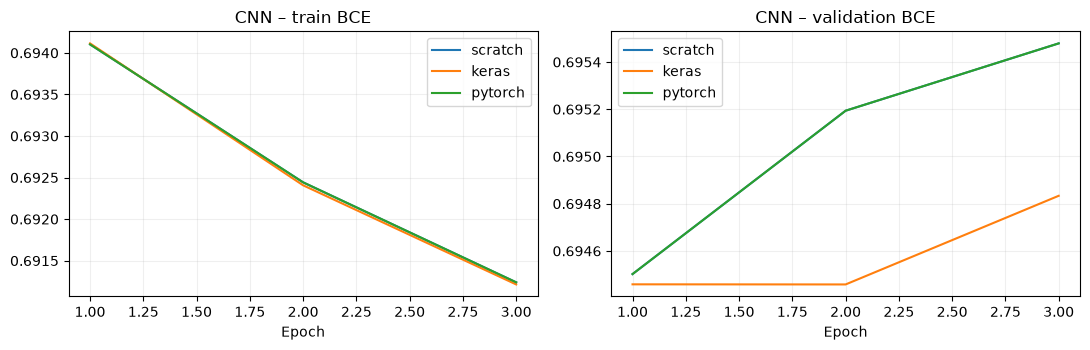

In [12]:
# Cell CNN-12
fig, axes = plt.subplots(1,2,figsize=(11,3.6))
for fw, history in curves.items():
    epochs = [r['epoch'] for r in history]
    axes[0].plot(epochs,[r['train_loss'] for r in history],label=fw)
    axes[1].plot(epochs,[r['val_loss'] for r in history],label=fw)
axes[0].set_title(KIND.upper()+' – train BCE')
axes[1].set_title(KIND.upper()+' – validation BCE')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT/(KIND+'_learning.png'),dpi=180)
plt.show()

## 3. Câu hỏi bảo vệ

    1. Hãy đọc biểu thức hợp hàm từ phải sang trái và chỉ shape tương ứng.
    2. Những lớp nào có tham số? Vì sao 20 thời điểm không thành 20 lớp?
    3. Vì sao phải align_weights trước khi so sánh?
    4. Gradient truyền qua từng hàm thế nào? Tại sao cần clipping?
    5. Loss giảm có bảo đảm AUC test tăng hay có lợi nhuận sau phí không?

    Kết quả trên tập con có thể dao động; phải báo cáo cả ba framework và
    giới hạn mẫu, không chọn riêng kết quả đẹp. Notebook không gửi lệnh giao dịch.